### Ridge Regression (L2 Regularization)

Ridge Regression is a regularized version of Linear Regression. It adds a penalty to the model's loss function based on the **squared values of the coefficients**. This discourages coefficients from becoming excessively large and can help reduce overfitting, especially when features are correlated.

The regularization strength is controlled by the parameter `alpha`:
- `alpha = 0`: no regularization; this is equivalent to ordinary least squares.
- A larger `alpha`: stronger penalty and generally smaller coefficients.
- An excessively large `alpha`: coefficients may become too small, causing underfitting.

Ridge Regression usually shrinks coefficients toward zero but does not make them exactly zero. Therefore, unlike Lasso, it does not perform automatic feature selection.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
from sklearn.datasets import load_diabetes

df = load_diabetes()

In [3]:
print(df.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [4]:
x = df.data
y = df.target

### Compare Linear Regression and Ridge Regression

We first use the Diabetes dataset and split it into training and testing sets. A Linear Regression model provides the baseline. We then train Ridge Regression with a very small `alpha` and compare the test-set R² score and RMSE.

**What to observe :** With a very small regularization strength, Ridge Regression should behave similarly to ordinary Linear Regression. The exact scores depend on the data split and model settings.

In [5]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=45)

In [6]:
from sklearn.linear_model import LinearRegression, Ridge

In [7]:
lr = LinearRegression()

In [8]:
lr.fit(x_train, y_train)

LinearRegression()

In [9]:
y_pred = lr.predict(x_test)

In [10]:
from sklearn.metrics import r2_score, mean_squared_error

print("R2 Score : ", r2_score(y_test, y_pred))
print("RMSE : ", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score :  0.5188113124539249
RMSE :  48.72713760953253


In [11]:
rd = Ridge(alpha=0.0001)

rd.fit(x_train, y_train)

Ridge(alpha=0.0001)

In [12]:
y_pred = rd.predict(x_test)
print("R2 Score : ", r2_score(y_test, y_pred))
print("RMSE : ", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score :  0.518973263588495
RMSE :  48.718937001819555


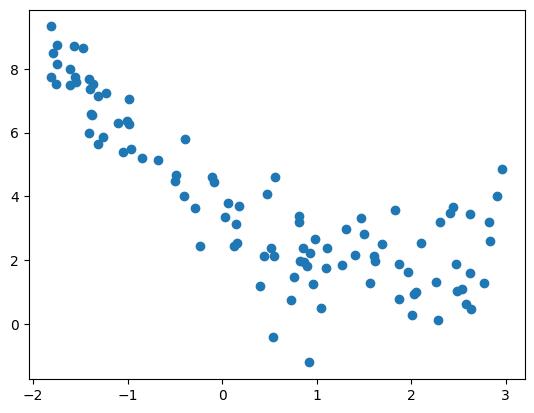

In [13]:
# genarate sample data 

m = 100
x1 = 5 * np.random.rand(m, 1) - 2
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 + np.random.randn(m,1)

plt.scatter(x1,x2);

In [14]:
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import PolynomialFeatures

def get_preds_ridge(x1, x2, alpha): 

    model = Pipeline([
        ('poly_feat', PolynomialFeatures(degree=16)), 
        ('ridge', Ridge(alpha))
    ])

    model.fit(x1, x2)

    return model.predict(x1)

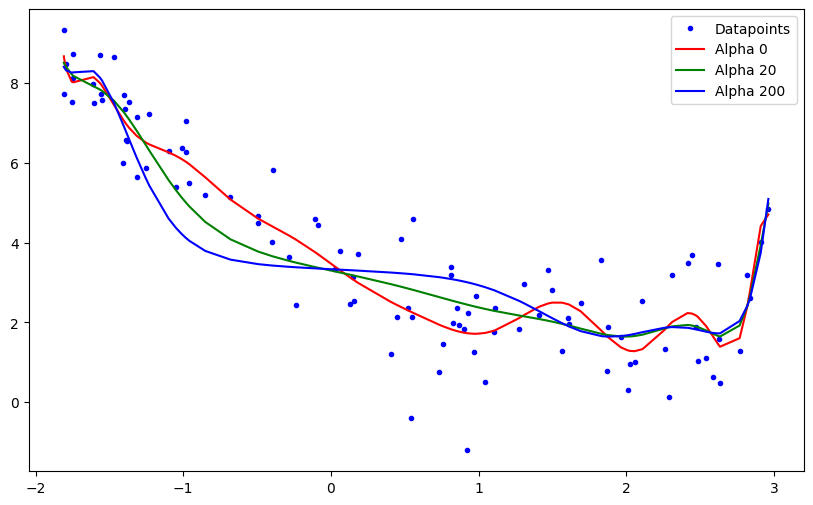

In [15]:
alphas = [0, 20, 200]
cs = ['r', 'g', 'b']

plt.figure(figsize=(10,6))
plt.plot(x1, x2, 'b.', label='Datapoints')

for alpha, c in zip(alphas, cs): 
    preds = get_preds_ridge(x1, x2, alpha)

    # plots 
    plt.plot(sorted(x1[:, 0]), preds[np.argsort(x1[:,0])], c, label = f'Alpha {alpha}')

plt.legend();

### Ridge Regression on Polynomial Data

A polynomial model can fit a curved relationship by creating higher-degree features. However, using a high polynomial degree can make the model overly flexible and cause overfitting.

Ridge Regression controls this flexibility by penalizing large coefficients. The plot compares fitted curves for different `alpha` values:
- `alpha = 0`: no Ridge penalty.
- Larger `alpha`: stronger coefficient shrinkage and a smoother, less flexible fit.

The goal is to balance fitting the training data with generalizing to unseen data.

### Key Understandings

#### 1. How are coefficients affected ? 

In [16]:
data = load_diabetes()

df = pd.DataFrame(data.data,columns=data.feature_names)
df['TARGET'] = data.target

In [17]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,TARGET
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [18]:
X_train,X_test,y_train,y_test = train_test_split(data.data,data.target,test_size=0.2,random_state=2)

In [19]:
coefs = []
r2_scores = []

for i in [0,10,100,1000]:
    reg = Ridge(alpha=i)
    reg.fit(X_train,y_train)
    
    coefs.append(reg.coef_.tolist())
    y_pred = reg.predict(X_test)
    r2_scores.append(r2_score(y_test,y_pred))

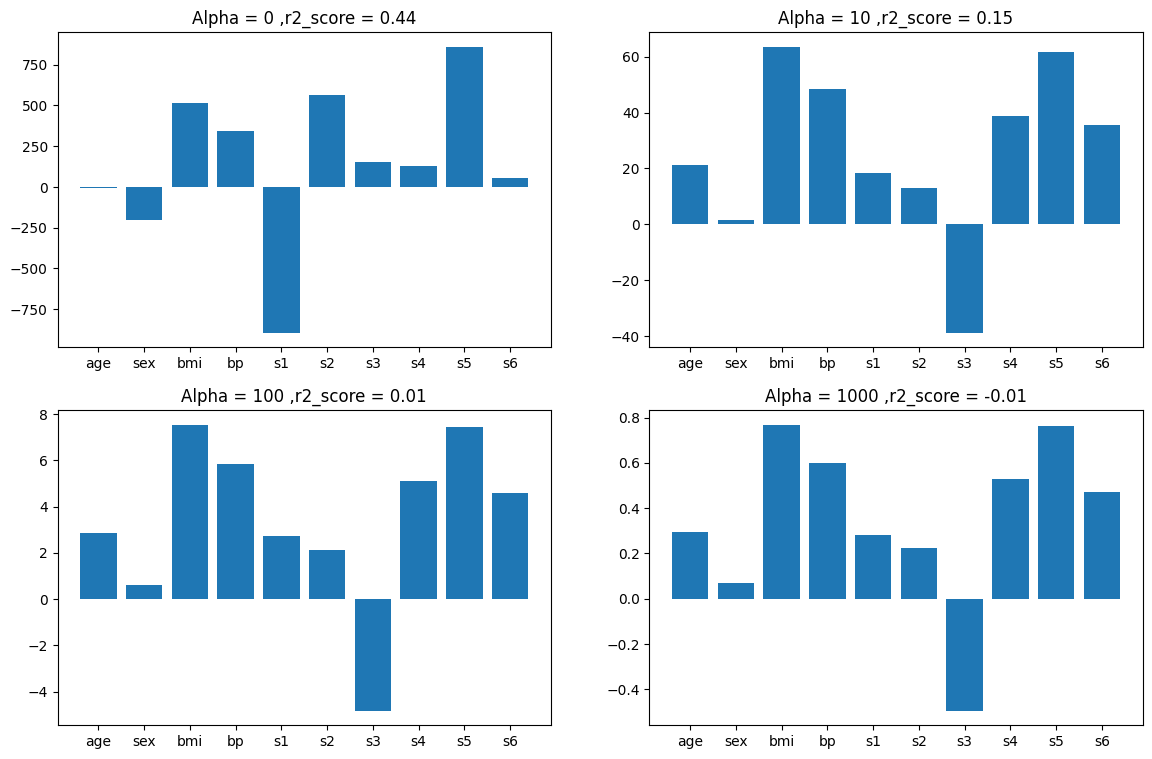

In [20]:
plt.figure(figsize=(14,9))
plt.subplot(221)
plt.bar(data.feature_names,coefs[0])
plt.title('Alpha = 0 ,r2_score = {}'.format(round(r2_scores[0],2)))

plt.subplot(222)
plt.bar(data.feature_names,coefs[1])
plt.title('Alpha = 10 ,r2_score = {}'.format(round(r2_scores[1],2)))

plt.subplot(223)
plt.bar(data.feature_names,coefs[2])
plt.title('Alpha = 100 ,r2_score = {}'.format(round(r2_scores[2],2)))

plt.subplot(224)
plt.bar(data.feature_names,coefs[3])
plt.title('Alpha = 1000 ,r2_score = {}'.format(round(r2_scores[3],2)))

plt.show()

#### 2. How Does Alpha Affect Coefficients ?

This section fits Ridge Regression with several `alpha` values and compares the learned coefficients.

The coefficient plots help show that increasing `alpha` generally pulls coefficients closer to zero. The amount of shrinkage can differ across features because their relationships with the target are different.

**Important :** Ridge Regression generally does not set coefficients exactly to zero. It reduces their magnitude.

In [21]:
alphas = [0,0.0001,0.001,0.01,0.1,1,10,100,1000,10000]

coefs = []

for i in alphas:
    reg = Ridge(alpha=i)
    reg.fit(X_train,y_train)
    
    coefs.append(reg.coef_.tolist())

In [22]:
input_array = np.array(coefs)

In [23]:
coef_df = pd.DataFrame(input_array,columns=data.feature_names)
coef_df['alpha'] = alphas
coef_df.set_index('alpha')

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.0000,-9.158653,-205.454322,516.693745,340.619999,-895.552002,561.220679,153.893110,126.731397,861.127002,52.421122
0.0001,-9.116119,-205.329219,516.889664,340.549436,-883.423872,551.559582,148.587063,125.353015,856.485935,52.468916
0.0010,-8.761487,-204.313404,518.380608,339.967926,-787.700510,475.282181,106.795253,114.629265,819.745723,52.873349
0.0100,-6.399507,-198.662945,522.056516,336.340595,-383.717571,152.670882,-66.053243,75.608209,659.875219,55.829221
0.1000,6.643733,-172.237474,485.529585,314.675846,-72.940209,-80.588688,-174.463527,83.614710,484.365316,73.585091
1.0000,42.242528,-57.304483,282.172125,198.059395,14.363734,-22.551079,-136.929684,102.023069,260.104294,98.552692
10.0000,21.174024,1.659837,63.659826,48.492858,18.421510,12.875466,-38.915435,38.842475,61.612302,35.505383
100.0000,2.858980,0.629453,7.540605,5.849949,2.710879,2.142135,-4.834047,5.108223,7.448451,4.576129
1000.0000,0.295726,0.069290,0.769004,0.597824,0.282900,0.225936,-0.495607,0.527031,0.761496,0.471029


In [24]:
alphas = [0,0.0001,0.0005,0.001,0.005,0.1,0.5,1,5,10]

coefs = []

for i in alphas:
    reg = Ridge(alpha=i)
    reg.fit(X_train,y_train)
    
    coefs.append(reg.coef_.tolist())

In [25]:
input_array = np.array(coefs)

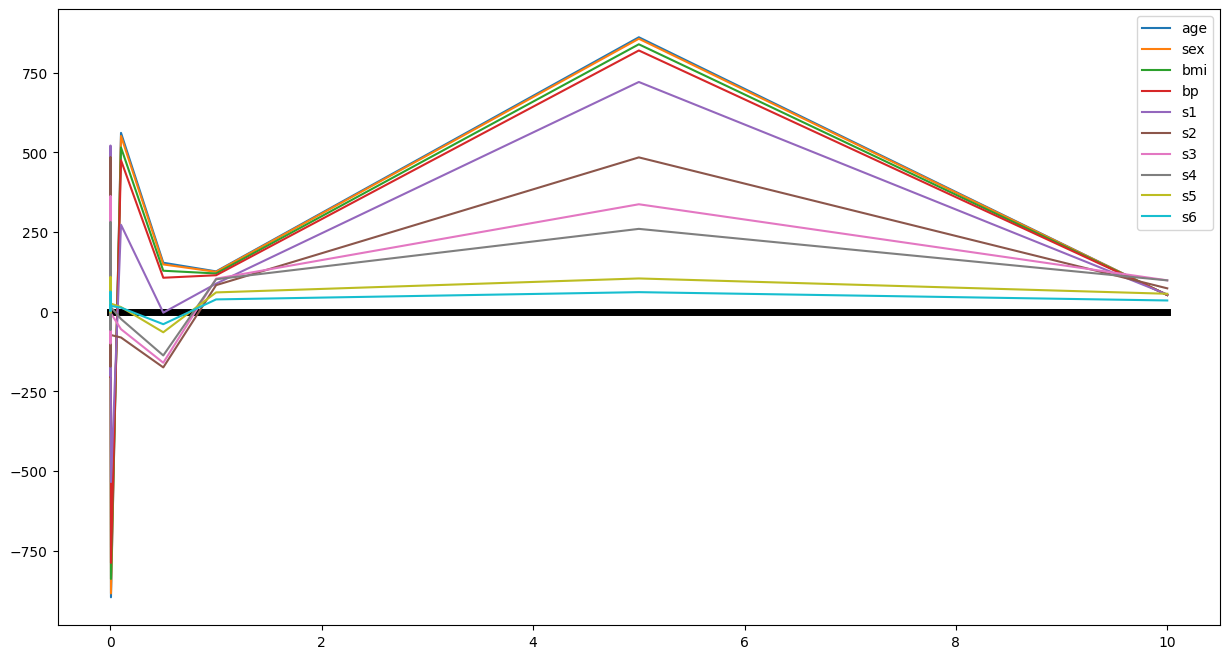

In [26]:
plt.figure(figsize=(15,8))
plt.plot(alphas,np.zeros(len(alphas)),color='black',linewidth=5)
for i in range(input_array.shape[0]):
    plt.plot(alphas,input_array[i],label=data.feature_names[i])
plt.legend()

#### 3. Impact on Bias and Variance

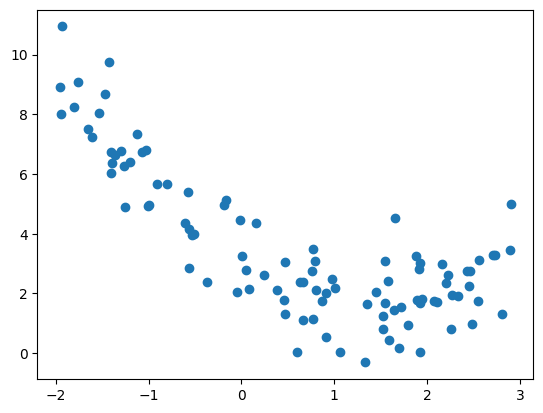

In [27]:
m = 100
X = 5 * np.random.rand(m, 1) - 2
y = 0.7 * X ** 2 - 2 * X + 3 + np.random.randn(m, 1)

plt.scatter(X, y)
plt.show()

In [28]:
X_train,X_test,y_train,y_test = train_test_split(X.reshape(100,1),y.reshape(100),test_size=0.2,random_state=2)

In [29]:
poly = PolynomialFeatures(degree=15)

X_train = poly.fit_transform(X_train)
X_test = poly.transform(X_test)

In [30]:
from mlxtend.evaluate import bias_variance_decomp

alphas = np.linspace(0,30,100)

loss = []
bias = []
variance = []

for i in alphas:
    reg = Ridge(alpha=i)
    avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        reg, X_train, y_train, X_test, y_test, 
        loss='mse',
        random_seed=123)
    loss.append(avg_expected_loss)
    bias.append(avg_bias)
    variance.append(avg_var)

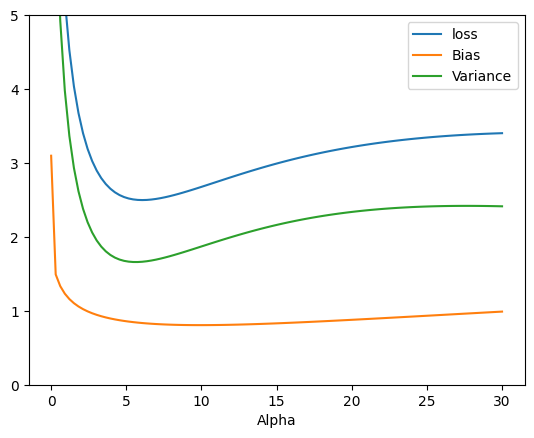

In [31]:
plt.plot(alphas,loss,label='loss')
plt.plot(alphas,bias,label='Bias')
plt.plot(alphas,variance,label='Variance')
plt.ylim(0,5)
plt.xlabel('Alpha')
plt.legend()

#### 4. Higher Coefficients and Regularization

This experiment tracks coefficient values over a wider range of `alpha` values.

Ridge applies an L2 penalty to all feature coefficients. A coefficient with a larger initial magnitude may show a larger absolute change, but the shrinkage is determined by the optimization problem and feature relationships—not by a simple rule that only the largest coefficient is penalized.

The coefficient paths help visualize how the fitted model changes as regularization becomes stronger.

[27.82809103]
-2.29474455867698


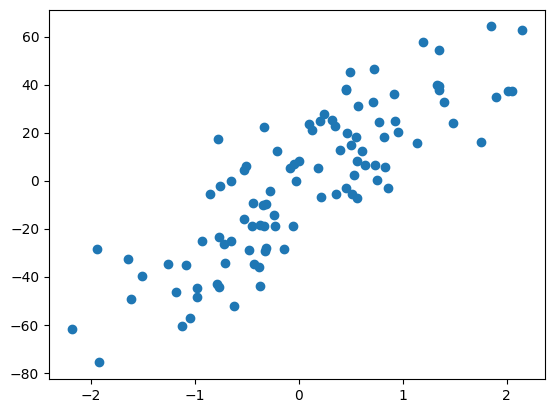

In [32]:
from sklearn.datasets import make_regression

X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

plt.scatter(X,y)

from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X,y)
print(reg.coef_)
print(reg.intercept_)

In [33]:
def cal_loss(m,alpha):
    return np.sum((y - m*X.ravel() + 2.29)**2) + alpha*m*m
    
def predict(m):
    return m*X - 2.29

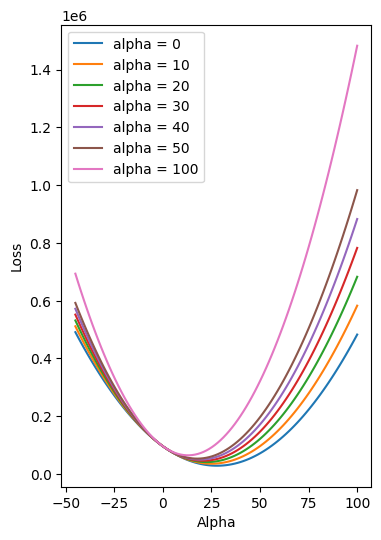

In [34]:
m = np.linspace(-45,100,100)
plt.figure(figsize=(4,6))
for j in [0,10,20,30,40,50,100]:
    loss = []
    for i in range(m.shape[0]):
        loss_i = cal_loss(m[i],j)
        loss.append(loss_i)
    plt.plot(m,loss,label='alpha = {}'.format(j))
plt.legend()
plt.xlabel('Alpha')
plt.ylabel('Loss')
plt.show()

### Effect of Regularization on the Loss Function

Ridge Regression minimizes an objective that combines prediction error and an L2 penalty:

$$J(\\mathbf{w}) = \\sum_{i=1}^{n}(y_i - \\hat{y}_i)^2 + \\alpha\\sum_{j=1}^{p}w_j^2$$

Here:
- $y_i$ is the actual target value.
- $\\hat{y}_i$ is the model prediction.
- $w_j$ is a feature coefficient.
- $\\alpha$ controls the strength of regularization.

The first term measures how well the model fits the data. The second term penalizes large coefficients. As `alpha` increases, the penalty becomes more influential, so the model prefers smaller coefficients even if the training error increases slightly.

In the code below, the loss is illustrated as a function of a single coefficient for several penalty strengths.

### Impact on Bias and Variance

This section creates a nonlinear dataset and expands the input into polynomial features. A high-degree polynomial model can have high variance and fit noise in the training data.

The `bias_variance_decomp` experiment estimates average expected loss, bias, and variance for different Ridge `alpha` values.

**General pattern:** Increasing regularization often increases bias while reducing variance. The best setting balances both and achieves a low expected prediction error. The relationship is not guaranteed to be perfectly smooth for every dataset.

### Key Takeaways

- Ridge Regression is Linear Regression with an **L2 penalty** on coefficient values.
- `alpha` controls regularization strength: larger values generally produce smaller coefficients.
- Ridge shrinks coefficients toward zero but usually does not make them exactly zero.
- Regularization can reduce overfitting by lowering model variance, although too much regularization can increase bias and cause underfitting.
- Feature scaling is important when input features have different scales because the L2 penalty acts on coefficient magnitudes.
- Choose `alpha` using cross-validation on the training data, then evaluate the selected model on a separate test set.